# Recomendador de jugadores (k-NN) + auditoría del plantel

Dos preguntas encadenadas:

1. **¿A quién conviene renovar?** Un semáforo clasifica al plantel en Renovación / Rotación / Prescindible / Baja. De ahí salen solos los puestos a reforzar.
2. **¿Quién lo reemplaza?** Para cada puesto flojo, el k-NN busca los *gemelos estadísticos* en las 36 plantillas de la categoría, con filtros de edad, minutos y valor de mercado.

### Qué es y qué NO es

Esto es un **embudo de preselección**, no un decisor. Reduce ~600 jugadores a una lista corta de 10-15 para que el cuerpo técnico los valide **por video**.

SofaScore no publica posicionamiento sin balón ni presión coordinada, así que hay cosas que el modelo no puede ver: si un central acompaña bien la línea, si un 5 tapa el pase interior, si un extremo hace el esfuerzo defensivo. Todo eso sigue siendo del ojo, no del dato.

Los criterios salen de `docs/especificacion_analisis_primera_b.md` y `docs/Criterios.txt`, podados a lo que el dataset banca de verdad (ver la última celda).

In [1]:
import os, sys
%load_ext autoreload
%autoreload 2
if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd(); sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import config
from src.analysis import scouting as sc
from src.analysis import similitud as sim
from src.visualization import scouting as vsc
from src.visualization.players import plot_players_radar
from IPython.display import Image, display

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

def show(p):
    if p and os.path.exists(p): display(Image(filename=p))

## 1. Configuración

In [2]:
# ============================================================
# CONFIGURAR ACÁ
SEASON       = '2026'
TEAM_SLUG    = 'chaco_for_ever'   # equipo a auditar
MIN_MINUTOS  = 600                # corte de muestra (§2.1 de la especificación)
K            = 15                 # cuántos gemelos devolver
REFRESCAR    = False              # True para releer todos los partidos (~30 s)
# ============================================================

OUT = config.scouting_dir(SEASON)
os.makedirs(OUT, exist_ok=True)
TEAM_ID = config.group_a_teams(SEASON).get(TEAM_SLUG, {}).get('id', config.CHACO_TEAM_ID)
print('Salidas ->', OUT)

Salidas -> c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\scouting


## 2. Pool de la categoría

Una fila por jugador de toda la Primera Nacional (Zona A + Zona B), con métricas por-90, ajuste por posesión (PAdj) y rol fino.

El rol **no** sale de la posición de SofaScore, que solo distingue G/D/M/F: sale de la **posición media en cancha**. La amplitud se mide en valor absoluto respecto del centro, porque un extremo que cambia de banda entre partidos promediaría el centro y quedaría mal clasificado.

In [3]:
pool = sc.pool_liga(SEASON, min_minutos=MIN_MINUTOS, refrescar=REFRESCAR)

print('\nJugadores por rol:')
print(pool['rol'].value_counts(dropna=False).to_string())
print('\nCobertura de datos:')
for c in ('edad', 'valor_mercado_eur', 'rating', 'pos_tabla', 'posesion',
          'km_recorridos'):
    print(f'  {c:20s} {pool[c].notna().mean():5.0%}')

Pool desde cache: c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\data\temporadas\2026\pool_scouting.csv
661 jugadores con 600+ minutos (de 1174 con minutos)

Jugadores por rol:
rol
DFC       132
LAT       118
DC        102
EXT_MP    100
MC         82
MCD        79
ARQ        48

Cobertura de datos:
  edad                   99%
  valor_mercado_eur      91%
  rating                100%
  pos_tabla             100%
  posesion              100%


In [4]:
# Control anti-doble-conteo: corre sobre el pool SIN filtrar por minutos
# (con el filtro faltarían los suplentes y no cerrarían los 11 en cancha).
_ = sc.verificar_pool(SEASON)

Partidos únicos: 593 · jugadores: 1127 · equipos: 36
Máx. partidos de un jugador : 33
Jugadores en cancha/partido : 10.91 a 11.02  (tiene que dar ~11)

OK: el pool no tiene doble conteo.


In [5]:
# Suavizado bayesiano (empuja los p90 de los de poca muestra hacia la mediana
# del rol) + percentiles por puesto + índices compuestos de la especificación.
pool = sc.suavizar_p90(pool)
pool = sc.scores_compuestos(pool)
pool.to_csv(os.path.join(OUT, 'pool_liga.csv'), index=False)

print('Mejores de cada puesto en la categoría:\n')
for rol in ('DFC', 'LAT', 'MCD', 'MC', 'EXT_MP', 'DC'):
    top = pool[pool.rol == rol].nlargest(3, 'score_rol')
    print(f'{rol:7s} {sc.ROL_NOMBRE[rol]}')
    for _, r in top.iterrows():
        print(f'        {r.nombre:22s} {str(r.equipo)[:26]:28s} {r.minutos:5.0f} min   score {r.score_rol:.1f}')
    print()

Mejores de cada puesto en la categoría:

DFC     Defensor central
        M. Guanini             Gimnasia y Tiro de Salta      2329 min   score 84.3
        F. Rivero              Colegiales                    2206 min   score 83.6
        D. Gissi               Nueva Chicago                 1593 min   score 82.9

LAT     Lateral / carrilero
        S. Corda               Club Ferro Carril Oeste       1098 min   score 88.6
        L. Faggioli            Deportivo Maipú               2571 min   score 82.3
        A. Ojeda               Chaco For Ever                1803 min   score 81.4

MCD     Mediocampista defensivo (5)
        E. Pérez               Deportivo Maipú                775 min   score 93.4
        J. D. Tomasso          Defensores de Belgrano        2444 min   score 86.5
        T. Guiacobini          Ciudad de Bolivar              735 min   score 81.4

MC      Mediocampista mixto
        B. Orosco              Godoy Cruz                     696 min   score 89.7
        G

## 3. Auditoría del plantel (semáforo de continuidad)

Cruza cuánto juega cada uno con cuánto rinde **respecto de su propio puesto en la categoría**.

El umbral de irregularidad del rating se calibra con la mediana real de la liga, no con el 0.65 del documento (que viene de otra categoría y acá aprobaría o reprobaría a todos).

Los arqueros quedan **sin evaluar** a propósito: SofaScore no publica `goals_prevented` y `saves` aparece en el 6% de los partidos, así que no hay con qué puntuarlos.

In [6]:
sem = sc.semaforo_plantel(pool, team_id=TEAM_ID)
sem.to_csv(os.path.join(OUT, f'semaforo_{TEAM_SLUG}.csv'), index=False)

display(sem[['nombre', 'rol', 'edad', 'pj', 'minutos', 'pct_minutos_equipo',
             'rating', 'score_pct', 'estado']])
print(sem.estado.value_counts().to_string())

,nombre,rol,edad,pj,minutos,pct_minutos_equipo,rating,score_pct,estado
0,R. Garay,DFC,29.6,23,1884.0,65.4,7.016054,77.3,PRIORIDAD_RENOVACION
1,G. Pacheco,DC,23.8,28,1820.0,63.2,6.928661,59.8,ROTACION_VALIOSA
2,A. Ojeda,LAT,25.2,24,1803.0,62.6,7.140681,98.3,ROTACION_VALIOSA
3,L. Fernandez,EXT_MP,31.7,14,1117.0,38.8,7.009348,61.0,ROTACION_VALIOSA
4,M. S. Romero,DC,32.3,11,897.0,31.1,7.448327,100.0,ROTACION_VALIOSA
5,M. Silvera,DFC,27.6,21,1505.0,52.3,6.910764,56.1,PRESCINDIBLE
6,A. Lioi,MC,29.6,22,1031.0,35.8,6.836597,50.6,PRESCINDIBLE
7,E. Gaggi,EXT_MP,28.7,15,948.0,32.9,7.081321,47.0,PRESCINDIBLE
8,S. Valenzuela,MC,25.0,20,884.0,30.7,6.751273,50.6,PRESCINDIBLE
9,M. D. Chaves,DC,23.1,20,694.0,24.1,6.601813,50.0,PRESCINDIBLE


estado
PRESCINDIBLE            6
BAJA_PRIORITARIA        6
ROTACION_VALIOSA        4
SIN_EVALUAR             2
PRIORIDAD_RENOVACION    1


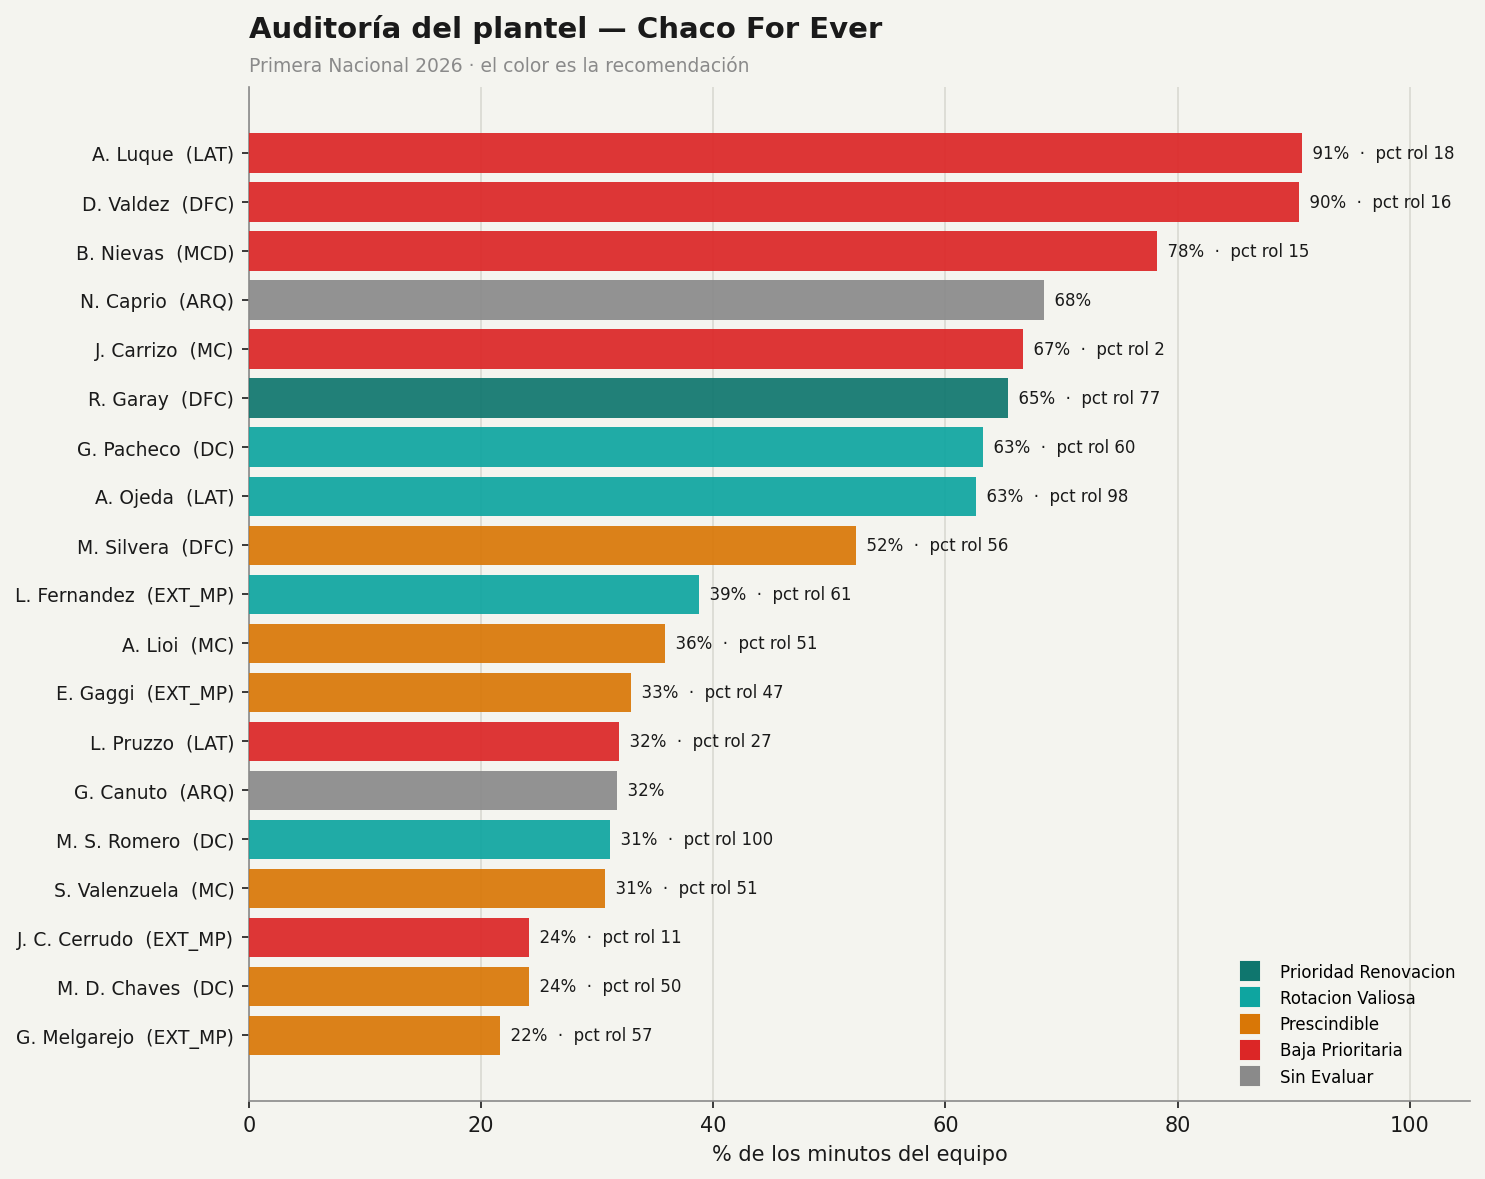

In [7]:
TEAM_NAME = pool.loc[pool.team_id == TEAM_ID, 'equipo'].mode().iat[0]
p = vsc.plot_semaforo(sem, title=f'Auditoría del plantel — {TEAM_NAME}',
                      subtitle=f'Primera Nacional {SEASON} · el color es la recomendación',
                      save_path=os.path.join(OUT, f'semaforo_{TEAM_SLUG}.png'))
show(p)

### Estadísticas del plantel que no entran en el score
Del JSON crudo y del shotmap: npxG, xGOT, goles sin penal, remates de cabeza y de
pelota parada, palos, regates intentados, veces que lo pasaron, % de regates
frenados, malos controles, penales, despejes en la línea, atajadas dentro del
área y km/sprints (estos dos casi no vienen en la categoría). El score y el k-NN
siguen con las métricas de la especificación; esto se lee al lado.

In [ ]:
COLS_EXTRA = ['nombre', 'rol', 'minutos', 'npxg', 'xgot', 'goles_sin_penal',
               'remates_cabeza', 'remates_pelota_parada', 'tiros_al_palo',
               'dribbles_attempted_p90', 'regateado_p90', 'regates_frenados_pct',
               'malos_controles_p90', 'penales_provocados', 'penales_cometidos',
               'penales_errados', 'despejes_en_linea', 'atajadas_dentro_area',
               'km_recorridos_p90', 'sprints_p90', 'pj_tracking']
extra = config.excluir_jugadores_fuera(pool[pool.team_id == TEAM_ID].copy(), col='nombre')
extra = extra.sort_values('minutos', ascending=False)[COLS_EXTRA]
extra.to_csv(os.path.join(OUT, f'estadisticas_extra_{TEAM_SLUG}.csv'), index=False)
display(extra.round(2))

## 4. Espacios de comparación por puesto

Un modelo k-NN **por rol**: comparar un central con un extremo no significa nada. Dentro del rol quedan ~70-120 jugadores con ~13 métricas, que es un espacio denso y sano.

La distancia va ponderada por los pesos del scoring model del puesto. Eso resuelve la redundancia (que seis métricas defensivas pesen seis veces) sin perder la interpretabilidad, que es lo que hace explicable la recomendación.

In [8]:
espacios = {r: sim.espacio_rol(pool, r, min_minutos=MIN_MINUTOS)
            for r in sim.FEATURES_ROL}
for r, e in espacios.items():
    print(f'{r:7s} {len(e):3d} jugadores · {len(e.features)} métricas')

DFC     132 jugadores · 13 métricas
LAT     118 jugadores · 13 métricas
MCD      79 jugadores · 13 métricas
MC       82 jugadores · 13 métricas
EXT_MP  100 jugadores · 13 métricas
DC      102 jugadores · 13 métricas


## 5. Buscar gemelos de un jugador

Cambiá `JUGADOR` por cualquiera del plantel (o de la liga) y volvé a correr desde acá.

In [9]:
# ============================================================
JUGADOR = 'B. Nievas'
FILTROS = {
    # 'edad_max': 26,
    # 'valor_max_eur': 200000,
    # 'minutos_min': 900,
    # 'pos_tabla_desde': 8,        # solo equipos de mitad de tabla para abajo
}
# ============================================================

ROL = pool.loc[pool.nombre == JUGADOR, 'rol'].iat[0]
esp = espacios[ROL]

gem = sim.gemelos(esp, nombre=JUGADOR, k=K, filtros=FILTROS or None,
                  excluir_mismo_equipo=True)
print(f'{JUGADOR} juega de {sc.ROL_NOMBRE[ROL]} ({len(esp)} en la categoría)\n')
display(gem[['nombre', 'equipo', 'edad', 'minutos', 'rating', 'score_pct',
             'valor_mercado_eur', 'pos_tabla', 'similitud']])

B. Nievas juega de Mediocampista defensivo (5) (79 en la categoría)



,nombre,equipo,edad,minutos,rating,score_pct,valor_mercado_eur,pos_tabla,similitud
0,M. Ribero,Central Norte de Salta,28.8,1468.0,6.831697,6.3,77000.0,15,64.1
1,A. Olinick,Racing de Córdoba,26.2,2175.0,7.047956,60.8,190000.0,13,58.5
2,T. Rodriguez,Nueva Chicago,24.6,1442.0,6.735922,36.7,180000.0,13,58.2
3,E. Britez,San Telmo,25.6,2377.0,6.850694,35.4,91000.0,12,56.2
4,M. Vázquez,CA Mitre,23.7,1643.0,6.700877,8.9,54000.0,14,56.1
5,F. Sivetti,Gimnasia y Tiro de Salta,28.4,1968.0,6.787257,5.1,54000.0,5,55.9
6,G. Mancuso,Central Norte de Salta,28.7,1769.0,6.668474,2.5,73000.0,15,55.2
7,S. Gauna,Almirante Brown,23.5,1112.0,6.966341,43.0,110000.0,6,53.9
8,F. Godoy,Güemes,36.4,1745.0,6.645158,12.7,24000.0,18,52.2
9,N. Previtali,Atlanta,31.3,1896.0,6.929430,57.6,370000.0,4,51.7


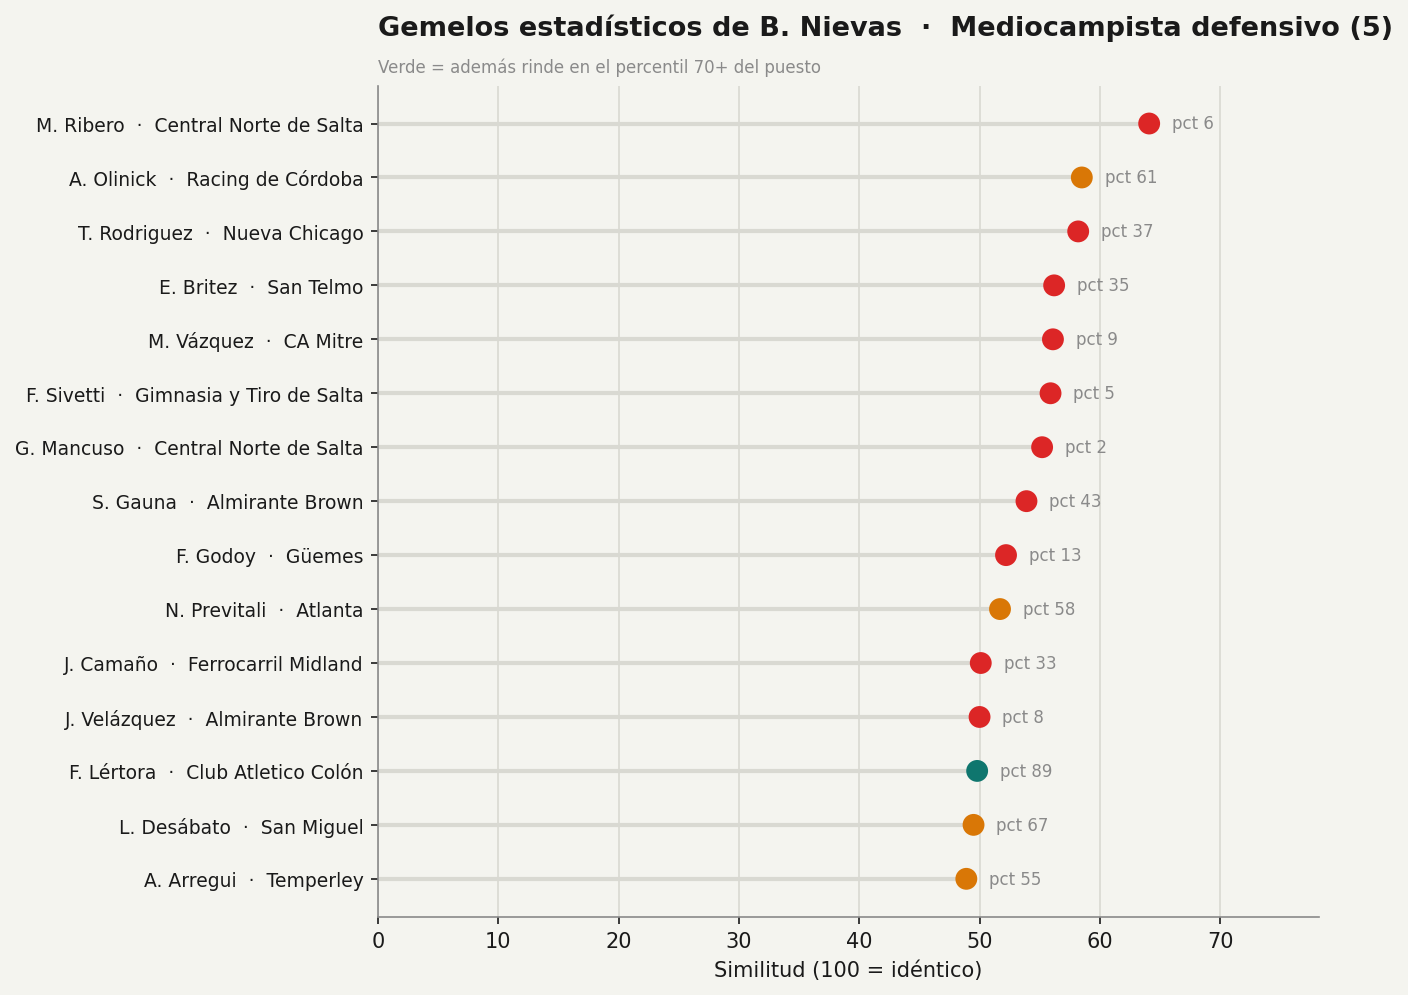

In [10]:
p = vsc.plot_gemelos(gem, JUGADOR, rol=sc.ROL_NOMBRE[ROL],
                     save_path=os.path.join(OUT, f'gemelos_{JUGADOR.replace(". ", "_").replace(" ", "_")}.png'))
show(p)

## 6. Cara a cara con un candidato

Radar contra los percentiles 5-95 **del puesto**, no de toda la liga.

B. Nievas  vs  M. Ribero (Central Norte de Salta)


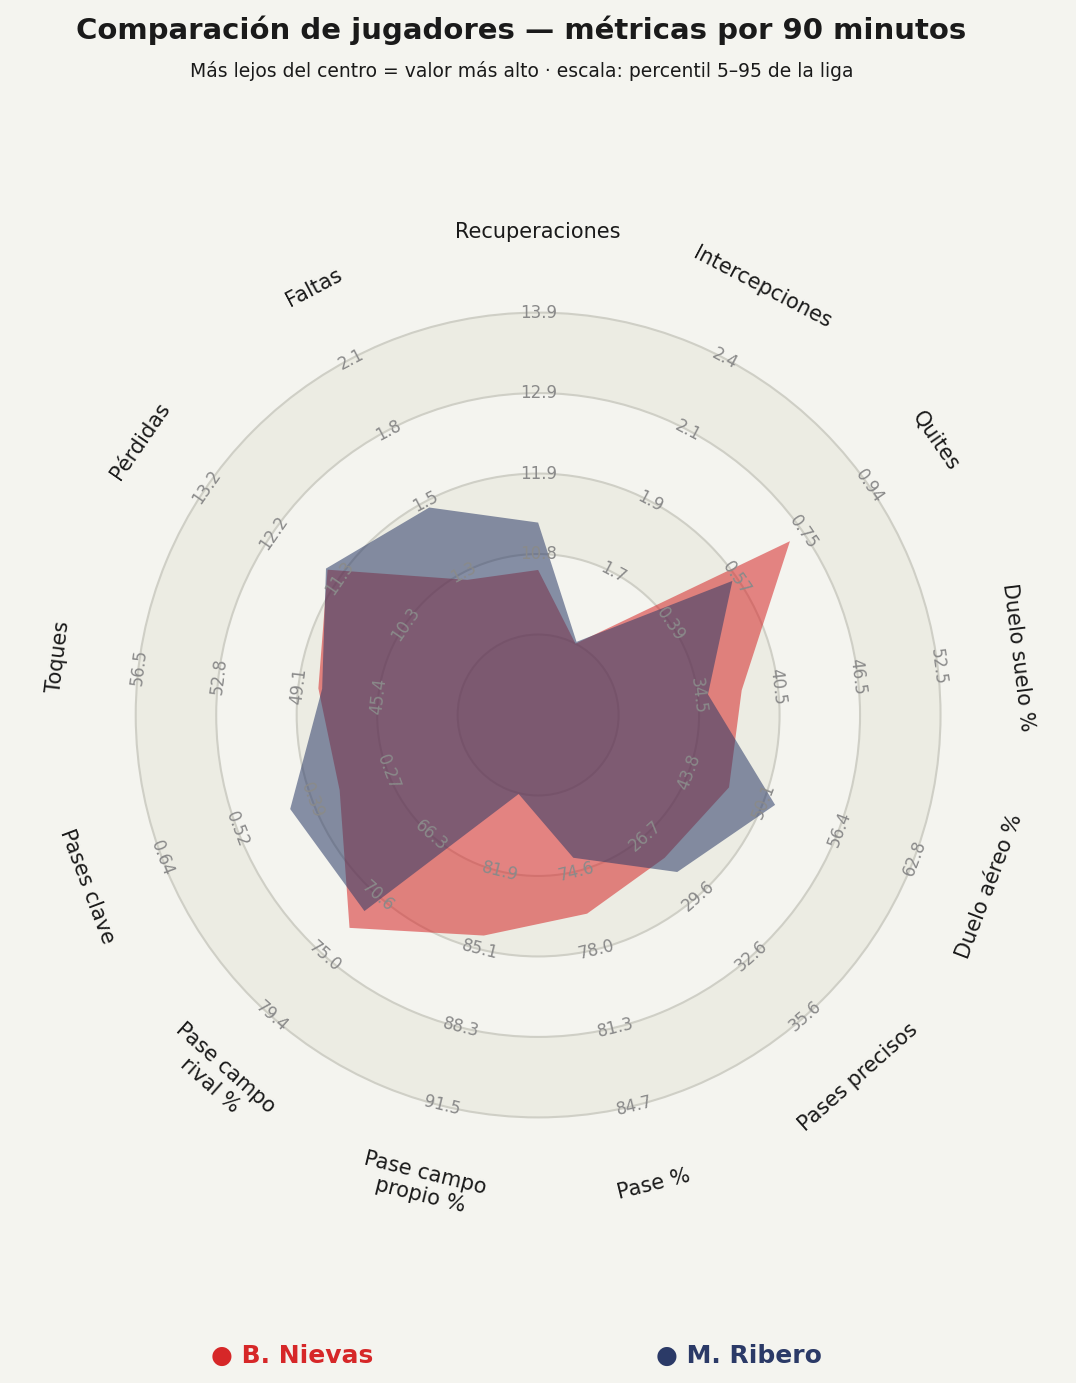

In [11]:
CANDIDATO = gem.iloc[0]   # cambiá el índice para comparar contra otro

id_actual = int(pool.loc[pool.nombre == JUGADOR, 'player_id'].iat[0])
cmp = sim.comparacion_desde_pool(pool, ROL, id_actual, int(CANDIDATO.player_id))
print(f'{cmp["player_a"]}  vs  {cmp["player_b"]} ({CANDIDATO.equipo})')

p = plot_players_radar(cmp, save_path=os.path.join(OUT, 'cara_a_cara.png'))
show(p)

## 7. Terna de fichajes por puesto flojo

Para cada jugador marcado Prescindible o Baja, tres perfiles buscados **entre sus gemelos** (no sobre toda la liga: dos jugadores con el mismo índice pueden jugar de formas opuestas).

- **Top performer** — rendimiento probado en la categoría
- **Moneyball** — rinde igual pero en un equipo de abajo, así que sale más barato
- **Apuesta** — sub-23 con una cualidad de desequilibrio en el top 10% del puesto

In [12]:
flojos = sem[(sem.tier >= 3) & (sem.tier < 5)]

for _, jug in flojos.iterrows():
    rol = jug['rol']
    if rol not in espacios:
        continue
    print('=' * 78)
    print(f"{jug['nombre']}  ·  {sc.ROL_NOMBRE[rol]}  ·  {jug['estado']}  "
          f"(pct {jug['score_pct']:.0f}, {jug['minutos']:.0f} min)")
    print('=' * 78)
    terna = sim.terna_fichajes(espacios[rol], pool, nombre=jug['nombre'])
    for perfil, d in terna.items():
        print(f'\n  ── {perfil.upper()} ──')
        if 'nota' in d.columns:
            print('     ' + d['nota'].iat[0])
            continue
        cols = ['nombre', 'equipo', 'edad', 'minutos', 'score_pct',
                'valor_mercado_eur', 'pos_tabla', 'similitud']
        print(d[cols].head(3).to_string(index=False))
    print()

M. Silvera  ·  Defensor central  ·  PRESCINDIBLE  (pct 56, 1505 min)

  ── TOP_PERFORMER ──
    nombre                   equipo  edad  minutos  score_pct  valor_mercado_eur  pos_tabla  similitud
  G. Canto  Club Ferro Carril Oeste  32.6   1868.0       81.1           165000.0          1       49.2
M. Guanini Gimnasia y Tiro de Salta  30.6   2329.0      100.0           230000.0          5       47.2
R. Zalazar            Nueva Chicago  21.8   1404.0       92.4            82000.0         13       44.6

  ── MONEYBALL ──
      nombre                 equipo  edad  minutos  score_pct  valor_mercado_eur  pos_tabla  similitud
  R. Zalazar          Nueva Chicago  21.8   1404.0       92.4            82000.0         13       44.6
F. Meritello              Patronato  30.6   2137.0       73.1           140000.0         16       45.5
 E. Calderón Central Norte de Salta  25.7   2340.0       71.2           165000.0         15       51.7

  ── APUESTA ──
    nombre        equipo  edad  minutos  score_p

## 8. Reemplazo de los TITULARES (prioridad de mercado)

Los dos pasos anteriores buscan *gemelos*, que es lo correcto cuando se va alguien bueno. Para
**mejorar** un puesto flojo el enfoque es otro: si el perfil del titular es el perfil mediocre del
puesto, sus vecinos también lo van a ser y fichar un clon es un movimiento lateral. `sim.mejoras()`
rankea el puesto por rendimiento y deja la similitud como dato secundario (qué tan fácil es meterlo
sin cambiar el funcionamiento del equipo).

La **urgencia** cruza cuánto juega con cuánto rinde: un suplente flojo no apura, un titular flojo sí.

En `LAT` y `EXT_MP` el filtro respeta la **banda**: proponer un lateral derecho para cubrir el
carril izquierdo no sirve de nada.


In [13]:
# Titulares (50%+ de los minutos) ordenados por urgencia de reemplazo.
plantel = config.excluir_jugadores_fuera(
    pool[pool.team_id == TEAM_ID].copy(), col='nombre')
plantel = plantel.merge(sem[['nombre', 'estado']], on='nombre', how='left')
plantel['urgencia'] = (plantel.pct_minutos_equipo
                       * (100 - plantel.score_pct.fillna(50)) / 100).round(1)

titulares = (plantel[(plantel.pct_minutos_equipo >= 50) & plantel.score_pct.notna()]
             .sort_values('urgencia', ascending=False))
titulares.to_csv(os.path.join(OUT, f'prioridad_titulares_{TEAM_SLUG}.csv'), index=False)

display(titulares[['nombre', 'rol', 'banda', 'edad', 'minutos', 'pct_minutos_equipo',
                   'rating', 'score_pct', 'valor_mercado_eur', 'urgencia', 'estado']])

,nombre,rol,banda,edad,minutos,pct_minutos_equipo,rating,score_pct,valor_mercado_eur,urgencia,estado
2,D. Valdez,DFC,NaN,33.5,2606.0,90.5,6.928180,16.3,69000.0,75.7,BAJA_PRIORITARIA
6,A. Luque,LAT,DER,27.6,2613.0,90.7,6.882600,17.8,160000.0,74.6,BAJA_PRIORITARIA
8,B. Nievas,MCD,NaN,28.4,2252.0,78.2,7.006599,15.2,135000.0,66.3,BAJA_PRIORITARIA
14,J. Carrizo,MC,NaN,25.9,1920.0,66.7,6.657610,2.4,105000.0,65.1,BAJA_PRIORITARIA
0,G. Pacheco,DC,NaN,23.8,1820.0,63.2,6.928661,59.8,48000.0,25.4,ROTACION_VALIOSA
9,M. Silvera,DFC,NaN,27.6,1505.0,52.3,6.910764,56.1,285000.0,23.0,PRESCINDIBLE
7,R. Garay,DFC,NaN,29.6,1884.0,65.4,7.016054,77.3,26000.0,14.8,PRIORIDAD_RENOVACION
18,A. Ojeda,LAT,IZQ,25.2,1803.0,62.6,7.140681,98.3,130000.0,1.1,ROTACION_VALIOSA


In [14]:
# Para cada titular urgente: dónde pierde + los mejores del puesto que lo superan.
URGENCIA_MIN = 25     # por debajo de esto el puesto no es prioridad
MARGEN_PCT   = 15     # percentiles que el candidato tiene que sacarle al actual

informe = []
for _, jug in titulares[titulares.urgencia >= URGENCIA_MIN].iterrows():
    rol = jug['rol']
    if rol not in espacios:
        continue
    banda = f" ({jug['banda']})" if pd.notna(jug['banda']) else ''
    print('=' * 92)
    print(f"{jug['nombre'].upper()}  ·  {sc.ROL_NOMBRE[rol]}{banda}  ·  {jug['edad']:.0f} años")
    print(f"{jug['minutos']:.0f} min ({jug['pct_minutos_equipo']:.0f}%) · "
          f"percentil {jug['score_pct']:.0f} del puesto · urgencia {jug['urgencia']:.0f}")
    print('=' * 92)

    print()
    print('  Dónde pierde:')
    dg = sim.diagnostico(pool, rol, nombre=jug['nombre'])
    for _, c in dg.iterrows():
        flag = '   <-- agujero' if c.percentil < 35 and c.peso >= 0.20 else ''
        print(f"    {c.componente:14s} peso {c.peso:.0%}  percentil {c.percentil:5.1f}"
              f"   [{c.metricas}]{flag}")

    m = sim.mejoras(espacios[rol], pool, nombre=jug['nombre'], k=6,
                    margen_pct=MARGEN_PCT)
    print()
    print('  Candidatos que lo superan:')
    if m.empty:
        print('    Ninguno supera el margen en la categoría.')
    else:
        display(m[['nombre', 'equipo', 'banda', 'edad', 'minutos', 'score_pct',
                   'delta_pct', 'valor_mercado_eur', 'pos_tabla', 'similitud']])
        m.insert(0, 'reemplaza_a', jug['nombre'])
        m.insert(1, 'puesto', rol)
        informe.append(m)
    print()

if informe:
    pd.concat(informe, ignore_index=True).to_csv(
        os.path.join(OUT, f'candidatos_titulares_{TEAM_SLUG}.csv'), index=False)

D. VALDEZ  ·  Defensor central  ·  34 años
2606 min (90%) · percentil 16 del puesto · urgencia 76

  Dónde pierde:
    duelo_aereo    peso 30%  percentil  12.1   [Duelo aéreo %]   <-- agujero
    duelo_suelo    peso 25%  percentil  33.3   [Duelo suelo %]   <-- agujero
    rating         peso 10%  percentil  38.6   [Rating]
    volumen_def    peso 20%  percentil  44.3   [Despejes, Intercepciones]
    salida         peso 15%  percentil  64.0   [Pelotas largas, Pase campo rival %]

  Candidatos que lo superan:


,nombre,equipo,banda,edad,minutos,score_pct,delta_pct,valor_mercado_eur,pos_tabla,similitud
0,M. Guanini,Gimnasia y Tiro de Salta,NaN,30.6,2329.0,100.0,83.7,230000.0,5,34.8
1,F. Rivero,Colegiales,NaN,33.2,2206.0,99.2,82.9,97000.0,9,33.2
2,D. Gissi,Nueva Chicago,NaN,35.4,1593.0,98.5,82.2,53000.0,13,39.7
3,G. Cepeda,Ferrocarril Midland,NaN,26.2,2276.0,97.7,81.4,140000.0,6,34.0
4,D. Viera,Godoy Cruz,NaN,35.4,1170.0,97.0,80.7,170000.0,3,38.5
5,A. Perez,Agropecuario Argentino,NaN,35.5,1170.0,96.2,79.9,93000.0,14,38.4



A. LUQUE  ·  Lateral / carrilero (DER)  ·  28 años
2613 min (91%) · percentil 18 del puesto · urgencia 75

  Dónde pierde:
    duelo_def      peso 25%  percentil  18.6   [Duelo suelo %]   <-- agujero
    creacion       peso 25%  percentil  22.9   [Pases clave, Toques]   <-- agujero
    recuperacion   peso 15%  percentil  34.7   [Recuperaciones]
    rating         peso 10%  percentil  48.3   [Rating]
    centro         peso 25%  percentil  60.6   [Centros precisos, Centro %]

  Candidatos que lo superan:


,nombre,equipo,banda,edad,minutos,score_pct,delta_pct,valor_mercado_eur,pos_tabla,similitud
0,S. Corda,Club Ferro Carril Oeste,ambas,31.3,1098.0,100.0,82.2,155000.0,1,38.8
1,L. Faggioli,Deportivo Maipú,DER,29.7,2571.0,99.2,81.4,220000.0,8,38.4
2,A. Ortega,Quilmes Atlético Club,DER,21.1,817.0,97.5,79.7,24000.0,12,36.5
3,D. Adín,San Miguel,DER,29.6,1753.0,96.2,78.4,110000.0,17,41.3
4,L. Arce,Godoy Cruz,DER,29.1,1296.0,93.2,75.4,875000.0,3,35.6
5,J. Galetto,Gimnasia y Tiro de Salta,DER,30.0,1659.0,86.4,68.6,73000.0,5,43.1



B. NIEVAS  ·  Mediocampista defensivo (5)  ·  28 años
2252 min (78%) · percentil 15 del puesto · urgencia 66

  Dónde pierde:
    recuperacion   peso 30%  percentil  13.9   [Recuperaciones, Intercepciones]   <-- agujero
    duelo_suelo    peso 25%  percentil  30.4   [Duelo suelo %]   <-- agujero
    bajo_presion   peso 10%  percentil  32.9   [Pase campo propio %]
    pase           peso 25%  percentil  39.2   [Pase %]
    rating         peso 10%  percentil  75.9   [Rating]

  Candidatos que lo superan:


,nombre,equipo,banda,edad,minutos,score_pct,delta_pct,valor_mercado_eur,pos_tabla,similitud
0,E. Pérez,Deportivo Maipú,NaN,40.6,775.0,100.0,84.8,97000.0,8,29.2
1,J. D. Tomasso,Defensores de Belgrano,NaN,33.3,2444.0,98.7,83.5,120000.0,11,38.0
2,T. Guiacobini,Ciudad de Bolivar,NaN,22.4,735.0,97.5,82.3,105000.0,8,38.3
3,F. Maidana,Gimnasia Jujuy,NaN,24.8,2421.0,96.2,81.0,570000.0,2,38.4
4,F. Recalde,Deportivo Madryn,NaN,30.2,2129.0,94.9,79.7,285000.0,4,40.4
5,L. Jara,Almirante Brown,NaN,35.4,1536.0,93.7,78.5,53000.0,6,33.9



J. CARRIZO  ·  Mediocampista mixto  ·  26 años
1920 min (67%) · percentil 2 del puesto · urgencia 65

  Dónde pierde:
    rating         peso 10%  percentil   6.1   [Rating]
    creacion       peso 25%  percentil   7.3   [Pases clave]   <-- agujero
    llegada        peso 15%  percentil   9.8   [Toques]
    progresion     peso 25%  percentil  26.2   [Regates ganados, Pase campo rival %]   <-- agujero
    presencia_def  peso 25%  percentil  32.3   [Quites, Intercepciones]   <-- agujero

  Candidatos que lo superan:


,nombre,equipo,banda,edad,minutos,score_pct,delta_pct,valor_mercado_eur,pos_tabla,similitud
0,B. Orosco,Godoy Cruz,NaN,28.6,696.0,100.0,97.6,220000.0,3,31.9
1,G. Castellani,Club Ferro Carril Oeste,NaN,39.2,733.0,98.8,96.4,23000.0,1,27.3
2,B. Cortés,Patronato,NaN,25.3,1433.0,97.6,95.2,180000.0,16,38.1
3,E. Hoyos,Club Ferro Carril Oeste,NaN,26.4,1840.0,96.3,93.9,430000.0,1,30.3
4,M. Roseti,Ferrocarril Midland,NaN,29.2,2346.0,95.1,92.7,220000.0,6,25.1
5,R. Castro,Agropecuario Argentino,NaN,33.3,2170.0,93.9,91.5,240000.0,14,42.2



G. PACHECO  ·  Delantero centro  ·  24 años
1820 min (63%) · percentil 60 del puesto · urgencia 25

  Dónde pierde:
    eficacia       peso 35%  percentil  37.5   [Goles, Conversión %]
    presencia_area peso 25%  percentil  52.9   [Toques, Tiros al arco]
    asociacion     peso 10%  percentil  52.9   [Asistencias, xA]
    rating         peso 10%  percentil  56.9   [Rating]
    juego_aereo    peso 20%  percentil  88.2   [Aéreos ganados, Duelo aéreo %]

  Candidatos que lo superan:


,nombre,equipo,banda,edad,minutos,score_pct,delta_pct,valor_mercado_eur,pos_tabla,similitud
0,A. Spetale,Quilmes Atlético Club,NaN,26.4,1654.0,99.0,39.2,73000.0,12,43.5
1,F. Fagundez,Deportivo Morón,NaN,27.8,2253.0,98.0,38.2,280000.0,2,33.6
2,L. Gordillo,Gimnasia y Tiro de Salta,NaN,27.5,2199.0,97.1,37.3,390000.0,5,44.1
3,M. Asenjo,Los Andes,NaN,32.2,2202.0,96.1,36.3,220000.0,9,48.5
4,I. Vera,Estudiantes de Buenos Aires,NaN,21.9,634.0,94.6,34.8,NaN,7,33.3
5,D. Becker,Tristán Suárez,NaN,28.9,1299.0,94.6,34.8,105000.0,1,41.6


In [15]:
# Dos recortes que suelen decidir la operación: proyección y presupuesto.
RECORTES = [('SUB-28 (reventa)',   {'edad_max': 27, 'minutos_min': 900}),
            ('BARATOS (<120k €)',  {'valor_max_eur': 120000, 'minutos_min': 1200})]

for etiqueta, filtros in RECORTES:
    print('#' * 92)
    print(f'#  {etiqueta}')
    print('#' * 92)
    for _, jug in titulares[titulares.urgencia >= URGENCIA_MIN].iterrows():
        rol = jug['rol']
        if rol not in espacios:
            continue
        m = sim.mejoras(espacios[rol], pool, nombre=jug['nombre'], k=4, filtros=filtros)
        print()
        print(f"{jug['nombre']} ({sc.ROL_NOMBRE[rol]}):")
        if m.empty:
            print('   sin opciones en ese rango que superen el margen')
            continue
        for _, c in m.iterrows():
            v = f"{c.valor_mercado_eur/1000:.0f}k" if pd.notna(c.valor_mercado_eur) else 's/valor'
            print(f"   {c.nombre:20s} {str(c.equipo)[:24]:26s} {c.edad:4.1f}a  "
                  f"{c.minutos:5.0f} min  pctil {c.score_pct:5.1f}  {v:>8s}  tabla {c.pos_tabla:2.0f}")
    print()

############################################################################################
#  SUB-28 (reventa)
############################################################################################

D. Valdez (Defensor central):
   G. Cepeda            Ferrocarril Midland        26.2a   2276 min  pctil  97.7      140k  tabla  6
   O. E. P. Oliveros    Temperley                  25.9a   2170 min  pctil  95.5   s/valor  tabla  3
   L. Pollacchi         San Telmo                  26.8a   2510 min  pctil  94.7      205k  tabla 12
   M. Tarón             Club Ferro Carril Oeste    26.6a   1026 min  pctil  93.9      170k  tabla  1

A. Luque (Lateral / carrilero):
   N. Kihm              Club Ferro Carril Oeste    21.3a   2030 min  pctil  79.7      195k  tabla  1
   B. Palazzo           Nueva Chicago              25.9a   1886 min  pctil  68.2      315k  tabla 13
   M. Vallejos          Quilmes Atlético Club      25.8a   1914 min  pctil  68.2      160k  tabla 12
   E. Cardozo          

## 9. Mapa del puesto

Los jugadores del puesto proyectados a dos dimensiones. Sirve para ver dónde cae el propio respecto de la categoría, y para detectar roles mal asignados: el que queda solo en un rincón suele estar mal etiquetado.


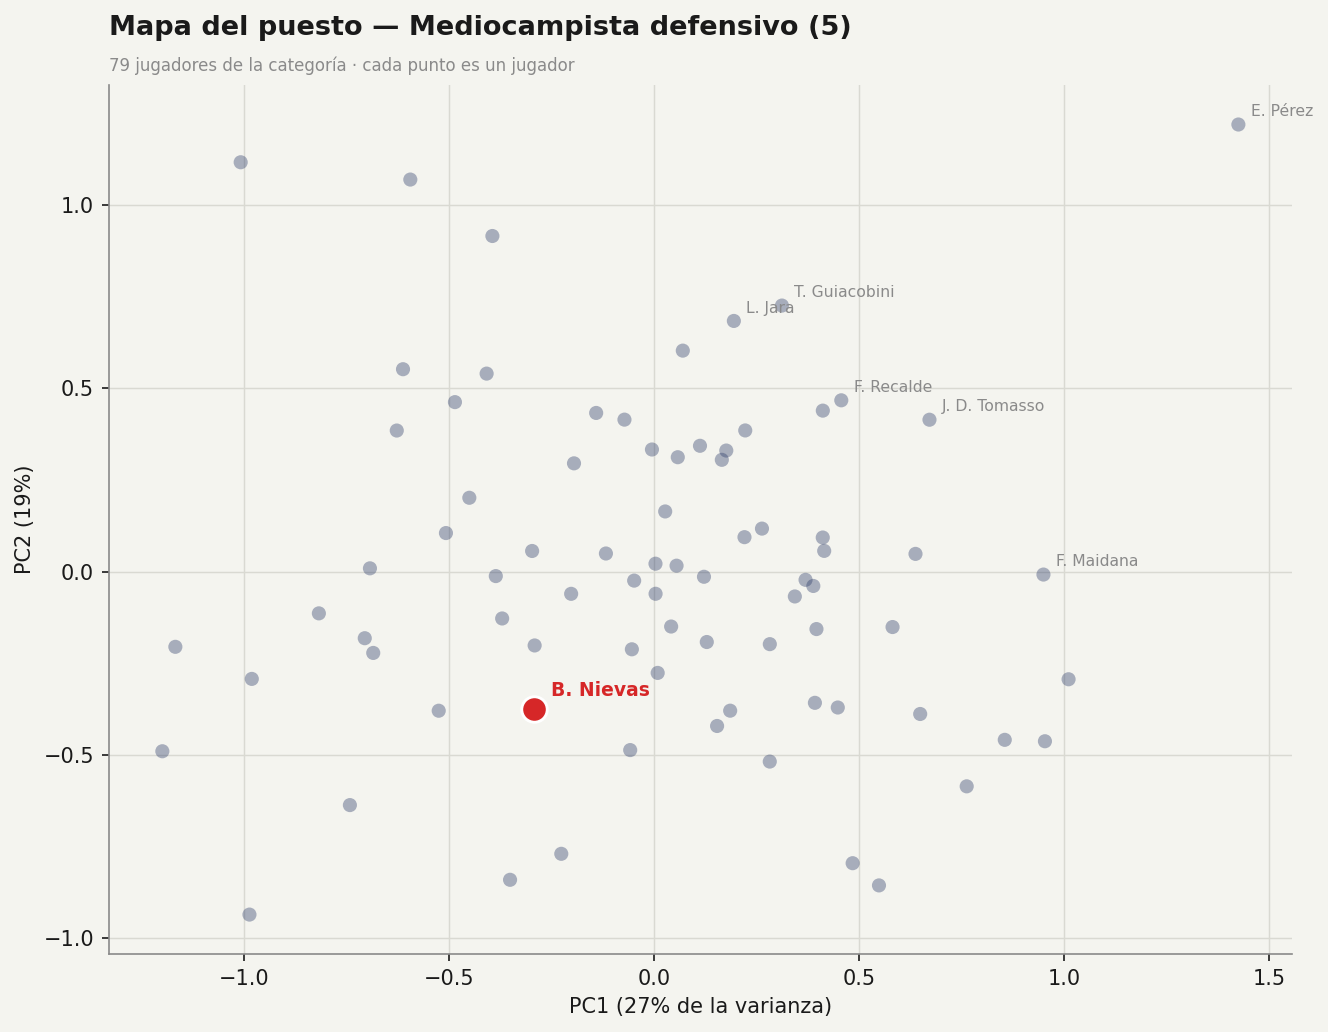

Varianza explicada por los dos ejes: (0.2702, 0.194)


In [16]:
mapa = sim.mapa_rol(espacios[ROL])
propios = list(pool.loc[(pool.team_id == TEAM_ID) & (pool.rol == ROL), 'nombre'])

p = vsc.plot_mapa_rol(mapa, destacar=propios, etiquetar_top=6,
                      rol=sc.ROL_NOMBRE[ROL],
                      save_path=os.path.join(OUT, f'mapa_{ROL}.png'))
show(p)
print('Varianza explicada por los dos ejes:', mapa.attrs['varianza'])

## Notas y limitaciones

**Lo que se recortó de la especificación, por datos que SofaScore no publica:**

| Pedido | Qué se hizo |
|---|---|
| Toques en el área | No existe. Se usa toques totales + xG |
| Pases al último tercio | Se sustituye por pases en campo rival (es medio campo, no último tercio) |
| Pases progresivos | No existe. Se reparte a pelotas largas + pases en campo rival |
| Duelos por zona de cancha | No existe. Se usan duelos terrestres globales |
| Masa salarial | No hay salarios. Se usa el valor de mercado de SofaScore |
| Score de arquero | Sin datos (`goals_prevented` vacía, `saves` al 6%) |

En cambio, sí se recuperaron del JSON crudo métricas que el CSV limpio no expone: **recuperaciones, bloqueos, errores que derivan en remate, quites ganados y pases por mitad de cancha**, más edad y valor de mercado. También quedan en el pool, fuera del score: **regates sufridos, malos controles, penales provocados/cometidos/errados, despejes en la línea, tiros al palo, atajadas dentro del área, km y sprints** (estos dos en el 1,6% de las filas), y del shotmap **npxG, xGOT y remates de cabeza / pelota parada**.

**Sesgos que hay que tener presentes:**

- El **contexto del equipo** no se corrige del todo. El ajuste por posesión (PAdj) compensa que un defensor de un equipo replegado infle despejes, pero no corrige la calidad del rival ni el estilo. Un 5 del puntero y uno de un equipo de abajo no son comparables aunque el k-NN los ponga cerca — por eso la tabla muestra siempre la posición del equipo.
- El perfil **Moneyball es explícitamente una apuesta** a que el rendimiento es del jugador y no del equipo que lo rodea.
- Con 600 minutos la muestra sigue siendo chica. El suavizado bayesiano lo mitiga, y la columna `muestra_chica` marca a los que están por debajo de 900.
- `nombre` es el nombre corto de SofaScore y hay homónimos: para desambiguar, usar `player_id`.

**El paso siguiente es el video.** Esta lista corta es el insumo del cuerpo técnico, no el final del proceso.